In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
path = "../data/raw/"
output_path = "../data/processed/"

In [14]:
patients = pd.read_stata(path + "patient.dta")

In [15]:
patients.head()


,patient_id,gender,age,district,state,country,location_type
0,3541,male,32,Nellore,Andhra Pradesh,India,urban
1,9299,female,54,Chandigarh,Chandigarh,India,NaN
2,4823,female,47,Pondicherry,Puducherry,India,urban
3,12486,female,34,Pondicherry,Puducherry,India,urban
4,1064,male,49,Cuddalore,Tamil Nadu,India,urban


In [16]:
print(patients.columns)

Index(['patient_id', 'gender', 'age', 'district', 'state', 'country',
       'location_type'],
      dtype='str')


In [17]:
visits = pd.read_stata(path + "patient2.dta")

In [18]:
visits.head()

,hospital_patient_rel_id,hospital_id,patient_id,admission_date,hospital_dept_id,ward_type,infection_type_id,clinical_diagnosis,comorbidity,devices_used,prior_admission
0,492592,4,1064,2023-02-24,Surgery,OPD,Community Acquired Infection,,,,NaN
1,493337,4,7235,2023-02-23,Surgery,Ward,Health Care Associated Infection,,,,NaN
2,508358,4,4823,2023-07-01,Endocrinology,OPD,Community Acquired Infection,,,,Ward
3,507281,4,4823,2023-06-13,Nephrology,ICU,Health Care Associated Infection,Renal transplantation,,Mechanical ventilator,NaN
4,531900,3,3541,2023-07-04,Pulmonary medicine,OPD,Not Known,ASTHMA MILD HAEMOPHILIA,,,NaN


In [19]:
samples= pd.read_stata(path + "patient3.dta")

In [20]:
samples.head()

,sample_id,hospital_patient_rel_id,patient_id,collection_date,sample_type_id,prescribed_antibiotic
0,519724,492592,1064,2023-02-24,Wound swab,
1,520597,493337,7235,2023-03-17,Blood-peripheral,
2,536921,507281,4823,2023-06-20,Sputum,"Inj. Magnex 2 gm,Tab. minocycline 200 mg"
3,538192,508358,4823,2023-07-01,Sputum,
4,539643,507281,4823,2023-06-23,BAL,"Inj. amikain 750 mg,Inj. Meropenem 2 gm"


In [21]:
results = pd.read_stata(
    path + "patient4.dta",
    convert_categoricals=False
)

In [22]:
results.head()

,amr_id,susceptibility_id,sample_id,hospital_patient_rel_id,patient_id,antibiotic_id,panel_id,special_test_type,special_test_id,organism_id,identification_method,susceptibility_test_type,value,remarks
0,553617,4882138,519724,492592,1064,1.0,2,NaN,NaN,5,4,2.0,25,1.0
1,553617,4882139,519724,492592,1064,7.0,2,NaN,NaN,5,4,2.0,25,2.0
2,553617,4882140,519724,492592,1064,9.0,2,NaN,NaN,5,4,2.0,24,1.0
3,553617,4882141,519724,492592,1064,34.0,2,NaN,NaN,5,4,2.0,27,1.0
4,553617,4882142,519724,492592,1064,11.0,2,NaN,NaN,5,4,2.0,26,1.0


In [23]:

print("patients:", patients.shape)
print("visits:  ", visits.shape)
print("samples: ", samples.shape)
print("results: ", results.shape)

print(samples["collection_date"].min())
print(samples["collection_date"].max())

patients: (10, 7)
visits:   (14, 11)
samples:  (16, 6)
results:  (140, 14)
2023-02-24
2023-12-28


In [50]:
tables = {"patients": patients, "visits": visits, "samples": samples, "results": results}

for name, table in tables.items():
    print("==", name, table.shape, "==")
    print(table.dtypes)
    print("Missing values per column:")
    print(table.isna().sum())

    empty_text = {}
    for col in table.columns:
        count = (table[col] == "").sum()
        if count > 0:
            empty_text[col] = count
    print("Empty text cells:", empty_text)
    print()

print("Skewness of age:", round(patients["age"].skew(), 2))
print("Kurtosis of age:", round(patients["age"].kurt(), 2))

== patients (10, 7) ==
patient_id          int32
gender           category
age                 int16
district         category
state            category
country          category
location_type    category
dtype: object
Missing values per column:
patient_id       0
gender           0
age              0
district         0
state            0
country          0
location_type    1
dtype: int64
Empty text cells: {}

== visits (14, 11) ==
hospital_patient_rel_id       int32
hospital_id                    int8
patient_id                    int32
admission_date                  str
hospital_dept_id           category
ward_type                  category
infection_type_id          category
clinical_diagnosis              str
comorbidity                     str
devices_used                    str
prior_admission            category
dtype: object
Missing values per column:
hospital_patient_rel_id     0
hospital_id                 0
patient_id                  0
admission_date              0
hospita

In [51]:
# 1. Look at the raw text in each column
print(visits["clinical_diagnosis"].tolist())
print(visits["comorbidity"].tolist())
print(visits["devices_used"].tolist())
print(samples["prescribed_antibiotic"].tolist())
print()

# 2. A function that splits one text cell into a set of clean items
def split_items(text):
    items = set()
    if pd.isna(text) or text == "":
        return items
    for piece in text.split(","):
        piece = piece.strip().lower()
        if piece != "":
            items.add(piece)
    return items

# 3. Collect the distinct items in each column
columns_to_check = {
    "clinical_diagnosis": visits["clinical_diagnosis"],
    "comorbidity": visits["comorbidity"],
    "devices_used": visits["devices_used"],
    "prescribed_antibiotic": samples["prescribed_antibiotic"],
}

for name, column in columns_to_check.items():
    distinct = set()
    for text in column:
        distinct.update(split_items(text))
    print(name, "->", len(distinct), "distinct items")
    print(sorted(distinct))
    print()

['', '', '', 'Renal transplantation', 'ASTHMA MILD HAEMOPHILIA', 'NULL', 'NULL', 'NULL', '', '', 'phemphigus vulgaris', 'phemphigus vulgaris', '', '']
['', '', '', '', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']
['', '', '', 'Mechanical ventilator', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']
['', '', 'Inj. Magnex 2 gm,Tab. minocycline 200 mg', '', 'Inj. amikain 750 mg,Inj. Meropenem 2 gm', 'Inj. amikacin 750 mg,Inj. meropenum 2 gm', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']

clinical_diagnosis -> 4 distinct items
['asthma mild haemophilia', 'null', 'phemphigus vulgaris', 'renal transplantation']

comorbidity -> 1 distinct items
['null']

devices_used -> 2 distinct items
['mechanical ventilator', 'null']

prescribed_antibiotic -> 7 distinct items
['inj. amikacin 750 mg', 'inj. amikain 750 mg', 'inj. magnex 2 gm', 'inj. meropenem 2 gm', 'inj. meropenum 2 gm', 'null', 'tab. minocycline 200 mg']



In [52]:
import re

spelling_fixes = {
    "amikain": "amikacin",
    "meropenum": "meropenem",
}

def clean_text_cell(text):
    # turns NaN, empty text and "NULL" into an empty string
    if pd.isna(text):
        return ""
    text = text.strip().lower()
    if text == "null":
        return ""
    return text

def clean_antibiotic(item):
    item = re.sub(r"^(inj|tab)\.\s*", "", item)               # remove "inj." or "tab." at the start
    item = re.sub(r"\s*\d+(\.\d+)?\s*(mg|gm|g)\b", "", item)  # remove doses like 750 mg or 2 gm
    item = item.strip()
    if item in spelling_fixes:
        item = spelling_fixes[item]
    return item

def get_antibiotics(text):
    text = clean_text_cell(text)
    names = set()
    if text == "":
        return names
    for piece in text.split(","):
        name = clean_antibiotic(piece.strip())
        if name != "":
            names.add(name)
    return names

samples["antibiotic_set"] = samples["prescribed_antibiotic"].apply(get_antibiotics)
print(samples[["sample_id", "prescribed_antibiotic", "antibiotic_set"]].to_string())

    sample_id                     prescribed_antibiotic         antibiotic_set
0      519724                                                               {}
1      520597                                                               {}
2      536921  Inj. Magnex 2 gm,Tab. minocycline 200 mg  {magnex, minocycline}
3      538192                                                               {}
4      539643   Inj. amikain 750 mg,Inj. Meropenem 2 gm  {amikacin, meropenem}
5      539645  Inj. amikacin 750 mg,Inj. meropenum 2 gm  {amikacin, meropenem}
6      566587                                                               {}
7      568935                                      NULL                     {}
8      571738                                      NULL                     {}
9      571748                                      NULL                     {}
10     580725                                                               {}
11     581846                                       

In [53]:
def split_clean(text):
    text = clean_text_cell(text)
    text = text.replace("phemphigus", "pemphigus")   # fix a spelling mistake
    items = set()
    if text == "":
        return items
    for piece in text.split(","):
        piece = piece.strip()
        if piece != "":
            items.add(piece)
    return items

def add_indicator_columns(table, set_column, prefix):
    all_items = set()
    for row_items in table[set_column]:
        all_items.update(row_items)

    new_columns = []
    for item in sorted(all_items):
        column_name = prefix + item.replace(" ", "_")
        values = []
        for row_items in table[set_column]:
            if item in row_items:
                values.append(1)
            else:
                values.append(0)
        table[column_name] = values
        new_columns.append(column_name)
    return new_columns

# antibiotics (already cleaned into sets)
rx_columns = add_indicator_columns(samples, "antibiotic_set", "prescribed_")

# diagnosis and devices (split and cleaned here)
visits["diagnosis_set"] = visits["clinical_diagnosis"].apply(split_clean)
visits["device_set"] = visits["devices_used"].apply(split_clean)

dx_columns = add_indicator_columns(visits, "diagnosis_set", "dx_")
device_columns = add_indicator_columns(visits, "device_set", "device_")

print(samples[rx_columns].sum())
print()
print(visits[dx_columns + device_columns].sum())

prescribed_amikacin       2
prescribed_magnex         1
prescribed_meropenem      2
prescribed_minocycline    1
dtype: int64

dx_asthma_mild_haemophilia      1
dx_pemphigus_vulgaris           2
dx_renal_transplantation        1
device_mechanical_ventilator    1
dtype: int64


In [24]:
with pd.read_stata(path + "patient4.dta", iterator=True) as reader:
    labels = reader.value_labels()

print(labels.keys())

dict_keys(['antibiotic_id', 'special_test_id', 'special_test_type', 'organism_id', 'panel_id', 'identification_method', 'remarks'])


In [25]:
results["antibiotic"] = results["antibiotic_id"].map(labels["antibiotic_id"])
results["organism"] = results["organism_id"].map(labels["organism_id"])
results["result"] = results["remarks"].map({1: "Susceptible", 2: "Intermediate", 3: "Resistant"})

print(results[["antibiotic", "organism", "value", "result"]].head(10))

                antibiotic               organism value        result
0                 Amikacin  Klebsiella pneumoniae    25   Susceptible
1               Cefotaxime  Klebsiella pneumoniae    25  Intermediate
2              Ceftazidime  Klebsiella pneumoniae    24   Susceptible
3              Ceftriaxone  Klebsiella pneumoniae    27   Susceptible
4            Ciprofloxacin  Klebsiella pneumoniae    26   Susceptible
5                 Imipenem  Klebsiella pneumoniae    27   Susceptible
6                Meropenem  Klebsiella pneumoniae    28   Susceptible
7  Piperacillin-tazobactam  Klebsiella pneumoniae    27   Susceptible
8                 Amikacin  Enterobacter cloacae     22   Susceptible
9               Cefotaxime  Enterobacter cloacae      6     Resistant


In [26]:
data = results.merge(samples[["sample_id", "collection_date"]], on="sample_id")

data["collection_date"] = pd.to_datetime(data["collection_date"])
data["month"] = data["collection_date"].dt.to_period("M")
data["is_resistant"] = (data["result"] == "Resistant").astype(int)

print(data.shape)
print(data[["collection_date", "month", "antibiotic", "organism", "result", "is_resistant"]].head())

(140, 20)
  collection_date    month     antibiotic               organism  \
0      2023-02-24  2023-02       Amikacin  Klebsiella pneumoniae   
1      2023-02-24  2023-02     Cefotaxime  Klebsiella pneumoniae   
2      2023-02-24  2023-02    Ceftazidime  Klebsiella pneumoniae   
3      2023-02-24  2023-02    Ceftriaxone  Klebsiella pneumoniae   
4      2023-02-24  2023-02  Ciprofloxacin  Klebsiella pneumoniae   

         result  is_resistant  
0   Susceptible             0  
1  Intermediate             0  
2   Susceptible             0  
3   Susceptible             0  
4   Susceptible             0  


In [27]:
# 1. Check the result column for missing values
print(data["result"].value_counts(dropna=False))

# 2. Resistance by antibiotic
by_antibiotic = data.groupby("antibiotic")["is_resistant"].agg(["count", "sum"])
by_antibiotic = by_antibiotic.rename(columns={"count": "tested", "sum": "resistant"})
by_antibiotic["percent_resistant"] = by_antibiotic["resistant"] / by_antibiotic["tested"] * 100
print(by_antibiotic.sort_values("percent_resistant", ascending=False))

# 3. Resistance by organism
by_organism = data.groupby("organism")["is_resistant"].agg(["count", "sum"])
by_organism = by_organism.rename(columns={"count": "tested", "sum": "resistant"})
by_organism["percent_resistant"] = by_organism["resistant"] / by_organism["tested"] * 100
print(by_organism.sort_values("percent_resistant", ascending=False))

result
Susceptible     70
Resistant       60
Intermediate     9
NaN              1
Name: count, dtype: int64
                               tested  resistant  percent_resistant
antibiotic                                                         
Ertapenem                           3          3         100.000000
Cefepime                            3          2          66.666667
Imipenem                           16          9          56.250000
Piperacillin-tazobactam            16          9          56.250000
Cefotaxime                         11          6          54.545455
Ciprofloxacin                      15          8          53.333333
Meropenem                          18          9          50.000000
Ceftazidime                         9          4          44.444444
Ceftriaxone                         9          4          44.444444
Amikacin                           15          5          33.333333
Levofloxacin                        4          1          25.000000
Cefoxit

In [28]:
# 1. Look at the row with the missing result
print(data[data["result"].isna()][["sample_id", "antibiotic", "organism", "value", "remarks"]])

# 2. Drop it
data = data.dropna(subset=["result"])
print(data.shape)

# 3. Organism table again, printed in full
by_organism = data.groupby("organism")["is_resistant"].agg(["count", "sum"])
by_organism = by_organism.rename(columns={"count": "tested", "sum": "resistant"})
by_organism["percent_resistant"] = by_organism["resistant"] / by_organism["tested"] * 100
print(by_organism.sort_values("tested", ascending=False).to_string())

     sample_id antibiotic               organism     value  remarks
108     586234        NaN  Staphylococcus aureus  Negative      NaN
(139, 20)
                              tested  resistant  percent_resistant
organism                                                          
Klebsiella pneumoniae             44         14          31.818182
Escherichia coli                  31         20          64.516129
Pseudomonas aeruginosa            17          0           0.000000
Acinetobacter baumannii           15         13          86.666667
Enterobacter cloacae              15         13          86.666667
Burkholderia cepacia complex       9          0           0.000000
Staphylococcus aureus              8          0           0.000000


organism
Acinetobacter baumannii         2
Burkholderia cepacia complex    1
Enterobacter cloacae            1
Escherichia coli                4
Klebsiella pneumoniae           6
Pseudomonas aeruginosa          2
Staphylococcus aureus           1
Name: sample_id, dtype: int64


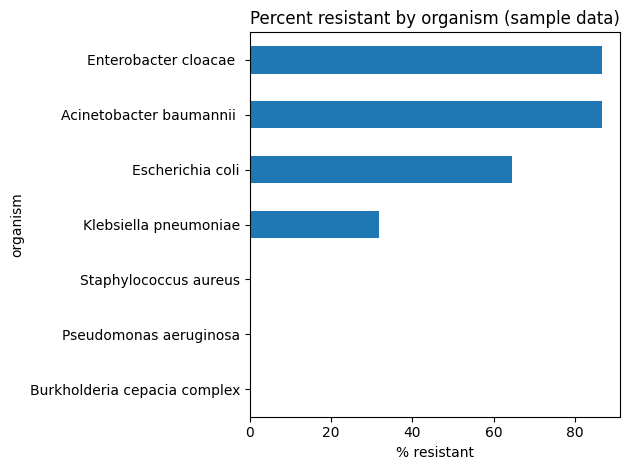

In [29]:
import matplotlib.pyplot as plt

# how many samples (not tests) each organism came from
print(data.groupby("organism")["sample_id"].nunique())

# bar chart of % resistant by organism
by_organism["percent_resistant"].sort_values().plot(kind="barh")
plt.xlabel("% resistant")
plt.title("Percent resistant by organism (sample data)")
plt.tight_layout()
plt.show()

In [30]:
per_sample = data.groupby(["sample_id", "organism"]).agg(
    tested=("is_resistant", "count"),
    resistant=("is_resistant", "sum")
).reset_index()

per_sample["percent_resistant"] = per_sample["resistant"] / per_sample["tested"] * 100
print(per_sample.to_string())

    sample_id                      organism  tested  resistant  percent_resistant
0      519724         Klebsiella pneumoniae       8          0           0.000000
1      520597         Enterobacter cloacae       15         13          86.666667
2      536921              Escherichia coli       7          6          85.714286
3      538192         Klebsiella pneumoniae       8          7          87.500000
4      539643      Acinetobacter baumannii        8          7          87.500000
5      539645        Pseudomonas aeruginosa       8          0           0.000000
6      566587        Pseudomonas aeruginosa       9          0           0.000000
7      568935      Acinetobacter baumannii        7          6          85.714286
8      571738              Escherichia coli       8          7          87.500000
9      571748              Escherichia coli       8          7          87.500000
10     571748         Klebsiella pneumoniae       7          6          85.714286
11     580725   

In [31]:
# which sample/organism/antibiotic combinations appear more than once
dups = data.groupby(["sample_id", "organism", "antibiotic"]).size()
print(dups[dups > 1])

# look at the 15 tests of that Enterobacter sample
print(data[data["sample_id"] == 520597][["antibiotic", "susceptibility_test_type", "value", "result"]].to_string())

sample_id  organism                      antibiotic                   
520597     Enterobacter cloacae          Amikacin                         2
                                         Ceftriaxone                      2
                                         Ciprofloxacin                    2
                                         Imipenem                         2
                                         Meropenem                        2
                                         Piperacillin-tazobactam          2
593721     Burkholderia cepacia complex  Ceftazidime                      2
                                         Meropenem                        2
                                         Minocycline                      2
                                         Trimethoprim-sulfamethoxazole    2
dtype: int64
                 antibiotic  susceptibility_test_type value       result
8                  Amikacin                       2.0    22  Susceptible
9         

In [32]:
keys = ["sample_id", "organism", "antibiotic"]

# 1. Do any duplicate tests disagree with each other?
check = data.groupby(keys)["remarks"].agg(["min", "max"])
print(check[check["min"] != check["max"]])

# 2. Keep one result per sample / organism / antibiotic (the highest code: 3 = Resistant)
clean = data.groupby(keys, as_index=False).agg(
    remarks=("remarks", "max"),
    collection_date=("collection_date", "first"),
    month=("month", "first")
)
clean["is_resistant"] = (clean["remarks"] == 3).astype(int)

print(data.shape[0], "->", clean.shape[0])

Empty DataFrame
Columns: [min, max]
Index: []
139 -> 129


In [33]:
per_sample = clean.groupby(["sample_id", "organism"]).agg(
    tested=("is_resistant", "count"),
    resistant=("is_resistant", "sum")
).reset_index()

per_sample["percent_resistant"] = per_sample["resistant"] / per_sample["tested"] * 100
print(per_sample.to_string())

clean.to_csv(path + "clean_results.csv", index=False)

    sample_id                      organism  tested  resistant  percent_resistant
0      519724         Klebsiella pneumoniae       8          0           0.000000
1      520597         Enterobacter cloacae        9          8          88.888889
2      536921              Escherichia coli       7          6          85.714286
3      538192         Klebsiella pneumoniae       8          7          87.500000
4      539643      Acinetobacter baumannii        8          7          87.500000
5      539645        Pseudomonas aeruginosa       8          0           0.000000
6      566587        Pseudomonas aeruginosa       9          0           0.000000
7      568935      Acinetobacter baumannii        7          6          85.714286
8      571738              Escherichia coli       8          7          87.500000
9      571748              Escherichia coli       8          7          87.500000
10     571748         Klebsiella pneumoniae       7          6          85.714286
11     580725   

In [34]:
info = per_sample.merge(samples[["sample_id", "hospital_patient_rel_id", "patient_id"]], on="sample_id")
info = info.merge(visits[["hospital_patient_rel_id", "ward_type", "infection_type_id"]], on="hospital_patient_rel_id")
info = info.merge(patients[["patient_id", "age", "gender"]], on="patient_id")

print(info.shape)
print(info[["sample_id", "organism", "percent_resistant", "ward_type", "infection_type_id", "age", "gender"]].to_string())

(17, 11)
    sample_id                      organism  percent_resistant ward_type                 infection_type_id  age  gender
0      519724         Klebsiella pneumoniae           0.000000       OPD      Community Acquired Infection   49    male
1      520597         Enterobacter cloacae           88.888889      Ward  Health Care Associated Infection   51    male
2      536921              Escherichia coli          85.714286       ICU  Health Care Associated Infection   47  female
3      538192         Klebsiella pneumoniae          87.500000       OPD      Community Acquired Infection   47  female
4      539643      Acinetobacter baumannii           87.500000       ICU  Health Care Associated Infection   47  female
5      539645        Pseudomonas aeruginosa           0.000000       ICU  Health Care Associated Infection   47  female
6      566587        Pseudomonas aeruginosa           0.000000       OPD                         Not Known   32    male
7      568935      Acinetobacte

In [35]:
info["highly_resistant"] = (info["percent_resistant"] > 50).astype(int)

print("unique patients:", info["patient_id"].nunique())
print()

for col in ["ward_type", "infection_type_id"]:
    summary = info.groupby(col)["highly_resistant"].agg(["count", "sum"])
    summary = summary.rename(columns={"count": "bacteria_rows", "sum": "highly_resistant"})
    print(summary)
    print()

unique patients: 10

           bacteria_rows  highly_resistant
ward_type                                 
ICU                    3                 2
OPD                    8                 2
Ward                   6                 4

                                  bacteria_rows  highly_resistant
infection_type_id                                                
Community Acquired Infection                  7                 1
Health Care Associated Infection              5                 3
Not Known                                     5                 4



In [47]:
ages = patients["age"]

mean = np.mean(ages)
median = np.median(ages)
mode = ages.mode().tolist()
value_range = ages.max() - ages.min()
variance = ages.var(ddof=0)
std_dev = np.sqrt(variance)

print("Mean:", round(mean, 2))
print("Median:", median)
print("Mode:", mode)
print("Range:", value_range)
print("Variance:", round(variance, 2))
print("Standard deviation:", round(std_dev, 2))
print()
print(ages.describe())

Mean: 39.7
Median: 43.5
Mode: [1, 29, 32, 34, 40, 47, 49, 51, 54, 60]
Range: 59
Variance: 258.81
Standard deviation: 16.09

count    10.000000
mean     39.700000
std      16.957791
min       1.000000
25%      32.500000
50%      43.500000
75%      50.500000
max      60.000000
Name: age, dtype: float64


remarks
Susceptible     65
Resistant       55
Intermediate     9
Name: count, dtype: int64


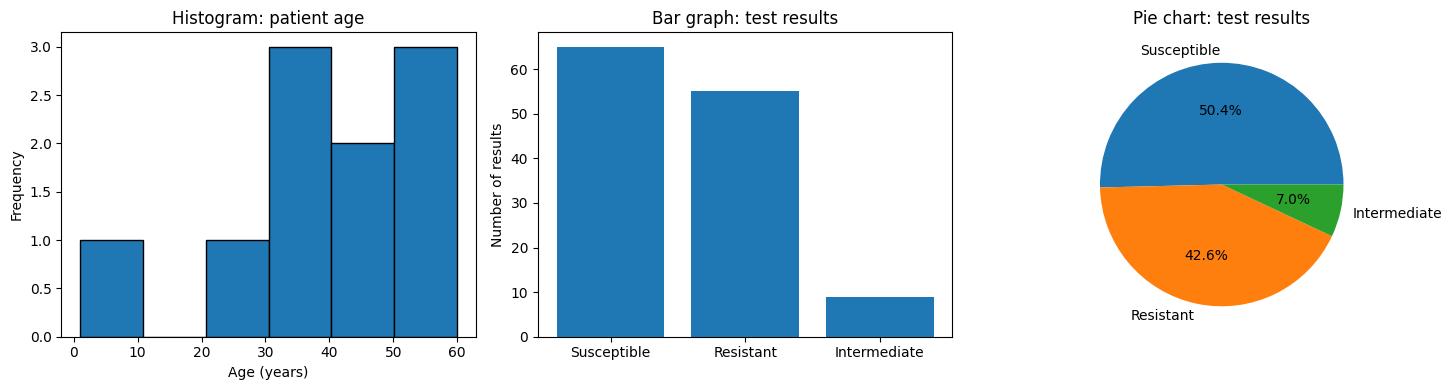

In [48]:
result_names = {1: "Susceptible", 2: "Intermediate", 3: "Resistant"}
result_counts = clean["remarks"].map(result_names).value_counts()
print(result_counts)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(ages, bins=6, edgecolor="black")
axes[0].set_title("Histogram: patient age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Frequency")

axes[1].bar(result_counts.index, result_counts.values)
axes[1].set_title("Bar graph: test results")
axes[1].set_ylabel("Number of results")

axes[2].pie(result_counts.values, labels=result_counts.index, autopct="%1.1f%%")
axes[2].set_title("Pie chart: test results")

plt.tight_layout()
plt.show()

IQR: 18.0 | bounds: 5.5 to 77.5
IQR outliers: [1]
Z-scores: [-0.48, 0.89, 0.45, -0.35, 0.58, 1.26, 0.02, -0.67, -2.41, 0.7]
Z-score outliers (|z| > 3): []


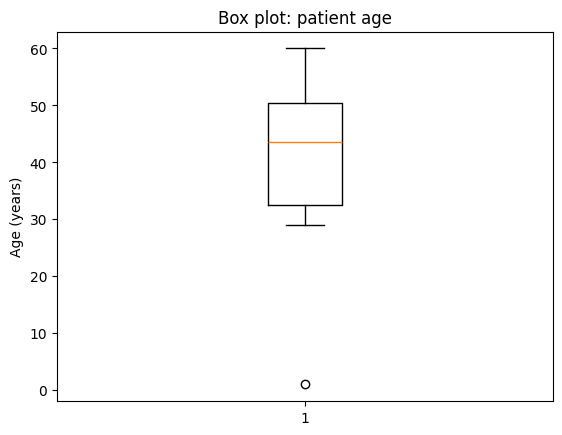

In [49]:
# IQR method
q1 = ages.quantile(0.25)
q3 = ages.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("IQR:", iqr, "| bounds:", lower, "to", upper)
print("IQR outliers:", ages[(ages < lower) | (ages > upper)].tolist())

# Z-score method
z_scores = (ages - ages.mean()) / ages.std(ddof=0)
print("Z-scores:", z_scores.round(2).tolist())
print("Z-score outliers (|z| > 3):", ages[abs(z_scores) > 3].tolist())

plt.boxplot(ages)
plt.title("Box plot: patient age")
plt.ylabel("Age (years)")
plt.show()

In [45]:
trends = pd.read_csv(path+"amr_trends.csv")

print(trends.shape)
print(trends.columns.tolist())
print(trends.head())

(1286, 13)
['organism', 'antibiotic', 'year', 'susceptible_n', 'tested_n', 'susceptible_pct', 'source_report_year', 'source_table', 'source_url', 'extracted_date', 'reported_pct', 'computed_pct', 'flags']
                  organism antibiotic  year  susceptible_n  tested_n  \
0  Acinetobacter baumannii   amikacin  2017            638      3312   
1  Acinetobacter baumannii   amikacin  2017            638      3312   
2  Acinetobacter baumannii   amikacin  2017            638      3312   
3  Acinetobacter baumannii   amikacin  2018            877      3795   
4  Acinetobacter baumannii   amikacin  2018            877      3795   

   susceptible_pct  source_report_year source_table  \
0             19.3                2022    Table 5.6   
1             19.3                2023    Table 4.3   
2             19.3                2024    Table 3.6   
3             23.1                2022    Table 5.6   
4             23.1                2023    Table 4.3   

                               

In [37]:
# 1. Keep only the newest report edition for each organism / antibiotic / year
trends = trends.sort_values("source_report_year")
latest = trends.drop_duplicates(subset=["organism", "antibiotic", "year"], keep="last")

# 2. Drop colistin (its numbers are intermediate %, not susceptibility)
latest = latest[latest["antibiotic"].str.lower() != "colistin"]

# 3. Checks
print(trends.shape, "->", latest.shape)
print(latest["susceptible_pct"].isna().sum(), "rows have no percentage")
print(latest["flags"].value_counts(dropna=False))
print(latest.groupby("organism")["antibiotic"].nunique())

(1286, 13) -> (478, 13)
12 rows have no percentage
flags
NaN                                                                       466
low_isolate_count_asterisk,pct_suppressed_in_source                        10
pct_suppressed_in_source                                                    1
low_isolate_count_asterisk,no_isolates_tested,pct_suppressed_in_source      1
Name: count, dtype: int64
organism
Acinetobacter baumannii     8
Escherichia coli           10
Klebsiella pneumoniae      10
MRSA                       11
Pseudomonas aeruginosa     10
Staphylococcus aureus      11
Name: antibiotic, dtype: int64


organism  antibiotic   
MRSA      cotrimoxazole    7
          linezolid        7
Name: year, dtype: int64
['cefoxitin', 'ciprofloxacin', 'clindamycin', 'cotrimoxazole', 'erythromycin', 'linezolid', 'oxacillin', 'teicoplanin', 'tetracycline', 'tigecycline', 'vancomycin']
     year  susceptible_n  tested_n  susceptible_pct
569  2017           2478      5147             48.1
572  2018           3832      7591             50.5
575  2019           6081     12164             50.0
578  2020           3660      7771             47.1
581  2021           5707     12678             45.0
584  2022           6404     14619             43.8
586  2023           2764      7335             37.6
587  2024           4276     12189             35.1


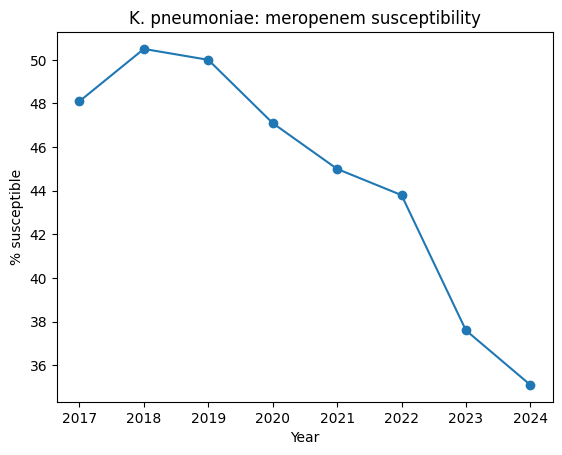

In [38]:
import matplotlib.pyplot as plt

# 1. Organism/antibiotic pairs that don't have all 8 years
years_per_pair = latest.groupby(["organism", "antibiotic"])["year"].nunique()
print(years_per_pair[years_per_pair < 8])

# 2. The MRSA antibiotic list
print(sorted(latest[latest["organism"] == "MRSA"]["antibiotic"].unique()))

# 3. One trend: Klebsiella pneumoniae vs meropenem
subset = latest[(latest["organism"] == "Klebsiella pneumoniae") & (latest["antibiotic"] == "meropenem")]
subset = subset.sort_values("year")
print(subset[["year", "susceptible_n", "tested_n", "susceptible_pct"]])

plt.plot(subset["year"], subset["susceptible_pct"], marker="o")
plt.xlabel("Year")
plt.ylabel("% susceptible")
plt.title("K. pneumoniae: meropenem susceptibility")
plt.show()

In [39]:
from sklearn.linear_model import LinearRegression

train = subset[subset["year"] <= 2022]
test = subset[subset["year"] > 2022]

model = LinearRegression()
model.fit(train[["year"]], train["susceptible_pct"])

predicted = model.predict(test[["year"]])

print("change per year:", round(model.coef_[0], 2))
for year, actual, pred in zip(test["year"], test["susceptible_pct"], predicted):
    print(year, "actual:", actual, "predicted:", round(pred, 1), "error:", round(pred - actual, 1))

change per year: -1.17
2023 actual: 37.6 predicted: 43.3 error: 5.7
2024 actual: 35.1 predicted: 42.2 error: 7.1


In [40]:
actual = test["susceptible_pct"].tolist()

# Model A: line on 2017-2022 (what you already ran)
pred_a = predicted.tolist()

# Model B: line on the last 4 training years only
recent = train[train["year"] >= 2019]
model_b = LinearRegression()
model_b.fit(recent[["year"]], recent["susceptible_pct"])
pred_b = model_b.predict(test[["year"]]).tolist()

# Baseline: repeat the last known value (2022)
last_value = train["susceptible_pct"].iloc[-1]
pred_c = [last_value] * len(actual)

def average_error(pred, actual):
    total = 0
    for p, a in zip(pred, actual):
        total = total + abs(p - a)
    return round(total / len(actual), 1)

print("Baseline (repeat 2022):", average_error(pred_c, actual))
print("Line on 2017-2022:     ", average_error(pred_a, actual))
print("Line on 2019-2022:     ", average_error(pred_b, actual))

Baseline (repeat 2022): 7.4
Line on 2017-2022:      6.4
Line on 2019-2022:      3.9


In [41]:
data_ok = latest.dropna(subset=["susceptible_pct"])

def average_error(pred, actual):
    total = 0
    for p, a in zip(pred, actual):
        total = total + abs(p - a)
    return total / len(actual)

rows = []

for (organism, antibiotic), group in data_ok.groupby(["organism", "antibiotic"]):
    group = group.sort_values("year")
    train_rows = group[group["year"] <= 2022]
    test_rows = group[group["year"] > 2022]
    recent_rows = train_rows[train_rows["year"] >= 2019]

    # skip pairs without enough data
    if len(test_rows) < 2 or len(recent_rows) < 4 or len(train_rows) < 5:
        continue

    actual = test_rows["susceptible_pct"].tolist()

    # baseline: repeat last known value
    pred_base = [train_rows["susceptible_pct"].iloc[-1]] * len(actual)

    # line on all training years
    model_all = LinearRegression()
    model_all.fit(train_rows[["year"]], train_rows["susceptible_pct"])
    pred_all = model_all.predict(test_rows[["year"]]).tolist()

    # line on 2019-2022 only
    model_recent = LinearRegression()
    model_recent.fit(recent_rows[["year"]], recent_rows["susceptible_pct"])
    pred_recent = model_recent.predict(test_rows[["year"]]).tolist()

    rows.append({
        "organism": organism,
        "antibiotic": antibiotic,
        "baseline": average_error(pred_base, actual),
        "all_years": average_error(pred_all, actual),
        "recent_years": average_error(pred_recent, actual),
    })

compare = pd.DataFrame(rows)
print("pairs tested:", len(compare))
print(compare[["baseline", "all_years", "recent_years"]].mean().round(2))

best = compare[["baseline", "all_years", "recent_years"]].idxmin(axis=1)
print(best.value_counts())

pairs tested: 56
baseline        3.36
all_years       3.20
recent_years    3.68
dtype: float64
all_years       26
baseline        19
recent_years    11
Name: count, dtype: int64


In [42]:
alert_rows = []

for (organism, antibiotic), group in data_ok.groupby(["organism", "antibiotic"]):
    group = group.sort_values("year")

    if len(group) < 6:
        continue

    model = LinearRegression()
    model.fit(group[["year"]], group["susceptible_pct"])

    slope = model.coef_[0]
    latest_value = group["susceptible_pct"].iloc[-1]
    forecast_2025 = model.predict(pd.DataFrame({"year": [2025]}))[0]
    forecast_2025 = max(0, min(100, forecast_2025))

    if slope <= -2 or latest_value < 40:
        risk = "High"
    elif slope <= -1:
        risk = "Medium"
    else:
        risk = "Low"

    alert_rows.append({
        "organism": organism,
        "antibiotic": antibiotic,
        "latest_pct": latest_value,
        "change_per_year": round(slope, 2),
        "forecast_2025": round(forecast_2025, 1),
        "risk": risk,
    })

alerts = pd.DataFrame(alert_rows)

print(alerts["risk"].value_counts())
print(alerts.sort_values("change_per_year").head(10).to_string())

risk
High      30
Low       23
Medium     5
Name: count, dtype: int64
                   organism               antibiotic  latest_pct  change_per_year  forecast_2025  risk
22    Klebsiella pneumoniae                 imipenem       31.20            -3.38           28.9  High
25    Klebsiella pneumoniae  piperacillin-tazobactam       26.00            -2.81           20.5  High
16         Escherichia coli  piperacillin-tazobactam       41.30            -2.76           35.7  High
20    Klebsiella pneumoniae            ciprofloxacin       20.40            -2.68           16.2  High
13         Escherichia coli                 imipenem       57.60            -2.58           55.9  High
53    Staphylococcus aureus                oxacillin       52.03            -2.49           47.0  High
4   Acinetobacter baumannii             levofloxacin       12.20            -2.15            7.9  High
24    Klebsiella pneumoniae                meropenem       35.10            -2.10           35.2  High
47 

In [43]:
def trend_label(slope):
    if slope <= -2:
        return "Falling fast"
    elif slope <= -1:
        return "Falling"
    else:
        return "Stable or rising"

def status_label(latest_pct):
    if latest_pct < 40:
        return "Below 40%"
    else:
        return "40% or above"

alerts["trend"] = alerts["change_per_year"].apply(trend_label)
alerts["status"] = alerts["latest_pct"].apply(status_label)

print(pd.crosstab(alerts["status"], alerts["trend"]))
print()

early = alerts[(alerts["status"] == "40% or above") & (alerts["trend"] != "Stable or rising")]
print(early.sort_values("change_per_year").to_string())

trend         Falling  Falling fast  Stable or rising
status                                               
40% or above        5             4                23
Below 40%           8             5                13

                  organism               antibiotic  latest_pct  change_per_year  forecast_2025    risk         trend        status
16        Escherichia coli  piperacillin-tazobactam       41.30            -2.76           35.7    High  Falling fast  40% or above
13        Escherichia coli                 imipenem       57.60            -2.58           55.9    High  Falling fast  40% or above
53   Staphylococcus aureus                oxacillin       52.03            -2.49           47.0    High  Falling fast  40% or above
47   Staphylococcus aureus                cefoxitin       47.61            -2.03           48.6    High  Falling fast  40% or above
42  Pseudomonas aeruginosa                 imipenem       56.90            -1.66           56.7  Medium       Falling  40% 

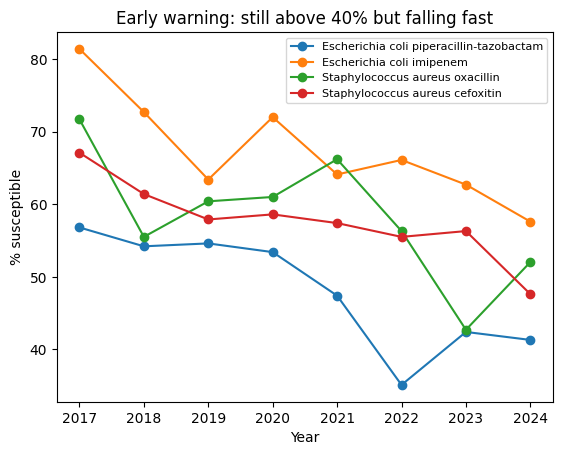

In [44]:
alerts.to_csv(path + "alerts.csv", index=False)
data_ok.to_csv(path + "clean_trends.csv", index=False)

top = early.sort_values("change_per_year").head(4)

for index, row in top.iterrows():
    group = data_ok[(data_ok["organism"] == row["organism"]) & (data_ok["antibiotic"] == row["antibiotic"])]
    group = group.sort_values("year")
    plt.plot(group["year"], group["susceptible_pct"], marker="o", label=row["organism"] + " " + row["antibiotic"])

plt.xlabel("Year")
plt.ylabel("% susceptible")
plt.title("Early warning: still above 40% but falling fast")
plt.legend(fontsize=8)
plt.show()